In [1]:
# Setup: run this cell first (needed on Google Colab; harmless elsewhere).
# Versions are pinned to the ones this workbook was tested with.
%pip install -q "qiskit==2.6.2" "qiskit-aer==0.18.4" "pylatexenc==2.11"

Note: you may need to restart the kernel to use updated packages.


# Workbook 3: Single-Qubit Gates and Circuits

**Quantum Computing Course, Workbook 3 of 14.** Prepared by Aditya Sharma.

Workbook 2 was about states and measurement. This workbook is about the operations in between: **gates**. Run the setup cell above first.

# How to use this workbook

Part A has the theory notes, Part B the exercises (easy, medium, hard, then Qiskit tasks) and Part C the answer key (instructor edition only). You need Workbook 1 (matrices, dagger, unitary, eigenvalues) and Workbook 2 (Born rule, Bloch sphere, measuring in the X and Y bases).

> **Note.** Boxes marked **Note** give tips and context. Boxes marked **Common mistake** flag errors that students make often.

## Learning outcomes

By the end of this workbook you should be able to:

1. Write the matrices of $X$, $Y$, $Z$, $H$, $S$, $T$, $R_X(\theta)$, $R_Y(\theta)$ and $R_Z(\theta)$, and apply them to states by hand.
2. Describe each gate as a rotation of the Bloch sphere (axis and angle).
3. Multiply gates in the right order for a circuit, and recognise when two circuits are equal up to global phase.
4. Use Qiskit's `QuantumCircuit`, `Operator` and `Statevector` to build circuits, get their matrices and check identities.
5. Run a single-qubit circuit on the Aer simulator and connect the histogram to the Born rule.

# Part A: Theory notes

## 3.1 Gates are unitary matrices

A **quantum gate** on one qubit is a $2\times2$ unitary matrix $U$. It turns the state $|\psi\rangle$ into $U|\psi\rangle$. Unitarity ($U^\dagger U = I$) does two jobs: it keeps the state normalised, and it makes every gate reversible, because $U^\dagger$ undoes $U$.

A **circuit** is a sequence of gates. In a circuit diagram time runs **left to right**. In the maths, the gate applied first sits **closest to the ket**. So the diagram "$A$ then $B$ then $C$" means

$$
|\psi_{\text{out}}\rangle = C\,B\,A\,|\psi_{\text{in}}\rangle .
$$

> **Common mistake.** Writing the matrices in diagram order, $ABC$. The order flips when you go from diagram to maths. Since gates usually do not commute (Workbook 1, Section 1.5), the wrong order usually gives the wrong answer.

**Equal up to global phase.** Two circuits $U$ and $V$ with $V = e^{i\gamma}U$ do exactly the same thing to every state, because a global phase never changes a measurement (Workbook 2, Section 2.3). Qiskit's `Operator.equiv` checks equality up to global phase.

## 3.2 The Pauli gates X, Y and Z

$$
X = \begin{pmatrix}0&1\\1&0\end{pmatrix}, \qquad Y = \begin{pmatrix}0&-i\\ i&0\end{pmatrix}, \qquad Z = \begin{pmatrix}1&0\\0&-1\end{pmatrix}.
$$

| Gate | On $\lvert 0\rangle$ | On $\lvert 1\rangle$ | Bloch sphere picture |
|---|---|---|---|
| $X$ | $\lvert 1\rangle$ | $\lvert 0\rangle$ | half turn ($180^\circ$) about the $x$ axis |
| $Y$ | $i\lvert 1\rangle$ | $-i\lvert 0\rangle$ | half turn about the $y$ axis |
| $Z$ | $\lvert 0\rangle$ | $-\lvert 1\rangle$ | half turn about the $z$ axis |

- $X$ is the quantum **NOT** gate. It swaps the amplitudes: $X(\alpha|0\rangle + \beta|1\rangle) = \beta|0\rangle + \alpha|1\rangle$.
- $Z$ is a **phase flip**. It leaves $|0\rangle$ alone and puts a minus sign on $|1\rangle$. It changes $|+\rangle$ into $|-\rangle$, which no Z-basis histogram can see but an X-basis measurement can.
- $Y = iXZ$. Up to a global phase, it is a bit flip and a phase flip together.

Useful facts: $X^2 = Y^2 = Z^2 = I$, and any two different Paulis **anticommute**, for example $XZ = -ZX$.

### Worked example 3.1

Apply $Z$ then $X$ to $|\psi\rangle = \frac{1}{\sqrt2}(|0\rangle + i|1\rangle) = |{+i}\rangle$. First $Z|\psi\rangle = \frac{1}{\sqrt2}(|0\rangle - i|1\rangle) = |{-i}\rangle$. Then $X$ swaps the amplitudes: $\frac{1}{\sqrt2}(-i|0\rangle + |1\rangle) = -i\cdot\frac{1}{\sqrt2}(|0\rangle + i|1\rangle)$. Up to the global phase $-i$, we are back at $|{+i}\rangle$. On the Bloch sphere: $Z$ turned $(0,1,0)$ to $(0,-1,0)$, and $X$ turned it back.

## 3.3 The Hadamard gate

$$
H = \frac{1}{\sqrt2}\begin{pmatrix}1&1\\1&-1\end{pmatrix}, \qquad H|0\rangle = |+\rangle,\quad H|1\rangle = |-\rangle,\quad H|+\rangle = |0\rangle,\quad H|-\rangle = |1\rangle .
$$

$H$ swaps the Z basis and the X basis. That is why Workbook 2 used it to measure in the X basis. On the Bloch sphere it is a half turn about the axis halfway between $x$ and $z$, which swaps the $x$ and $z$ axes and flips $y$. Three identities follow:

$$
H^2 = I, \qquad HXH = Z, \qquad HZH = X .
$$

### Worked example 3.2: interference

Start in $|0\rangle$ and apply $H$ twice. After one $H$ the state is $|+\rangle$, and a Z measurement would give 0 or 1 with probability $\frac12$ each. After the second $H$:

$$
H|+\rangle = \tfrac{1}{\sqrt2}\left(H|0\rangle + H|1\rangle\right) = \tfrac12\left(|0\rangle + |1\rangle\right) + \tfrac12\left(|0\rangle - |1\rangle\right) = |0\rangle .
$$

The two contributions to $|1\rangle$ cancel and the two contributions to $|0\rangle$ add. This is **interference**. The output is 0 every time. A coin flipped twice would still be random, so a qubit in $|+\rangle$ is not just a coin that has not landed yet.

> **Common mistake.** Describing $H$ as a gate that "makes the qubit random" or that is the source of quantum speed-ups by itself. $H$ is an ordinary unitary change of basis. Single-qubit gates alone are easy to simulate on a laptop. Any advantage needs many qubits, entanglement and carefully arranged interference, which later workbooks study honestly.

## 3.4 Phase gates S, T and P

These gates leave $|0\rangle$ alone and multiply $|1\rangle$ by a phase:

$$
P(\lambda) = \begin{pmatrix}1&0\\0&e^{i\lambda}\end{pmatrix}, \qquad S = P(\tfrac{\pi}{2}) = \begin{pmatrix}1&0\\0&i\end{pmatrix}, \qquad T = P(\tfrac{\pi}{4}) = \begin{pmatrix}1&0\\0&e^{i\pi/4}\end{pmatrix}.
$$

They change only the relative phase. On the Bloch sphere, $P(\lambda)$ turns the state by angle $\lambda$ about the $z$ axis. So $S$ is a quarter turn and $T$ is an eighth of a turn. Also $T^2 = S$, $S^2 = Z$ and $Z = P(\pi)$.

Their inverses are $S^\dagger = P(-\frac{\pi}{2})$ and $T^\dagger = P(-\frac{\pi}{4})$. Qiskit calls them `sdg` and `tdg`.

### Worked example 3.3

$S|+\rangle = \frac{1}{\sqrt2}(|0\rangle + i|1\rangle) = |{+i}\rangle$. On the Bloch sphere, a quarter turn about $z$ takes $(1,0,0)$ to $(0,1,0)$. Measured in the Z basis, $|+\rangle$ and $S|+\rangle$ both give 50/50. Phase gates are invisible to a Z measurement placed straight after them.

## 3.5 Rotation gates RX, RY and RZ

The rotation gates turn the Bloch sphere by any angle $\theta$ about the $x$, $y$ or $z$ axis. Qiskit (and this course) uses

$$
R_X(\theta) = \begin{pmatrix}\cos\frac{\theta}{2} & -i\sin\frac{\theta}{2}\\ -i\sin\frac{\theta}{2} & \cos\frac{\theta}{2}\end{pmatrix}, \quad
R_Y(\theta) = \begin{pmatrix}\cos\frac{\theta}{2} & -\sin\frac{\theta}{2}\\ \sin\frac{\theta}{2} & \cos\frac{\theta}{2}\end{pmatrix}, \quad
R_Z(\theta) = \begin{pmatrix}e^{-i\theta/2} & 0\\ 0 & e^{i\theta/2}\end{pmatrix}.
$$

All three have the same shape: $R_P(\theta) = \cos\frac{\theta}{2}\,I - i\sin\frac{\theta}{2}\,P$ for $P = X, Y, Z$ (you prove this in H1). The half angles mean that a turn of $\theta$ on the Bloch sphere needs $\theta/2$ in the matrix, just as $\theta/2$ appeared in the Bloch form of a state.

Links to the earlier gates:

- $R_Z(\lambda) = e^{-i\lambda/2}P(\lambda)$: the same rotation as the phase gate, up to global phase. So $S \equiv R_Z(\frac{\pi}{2})$ and $T \equiv R_Z(\frac{\pi}{4})$ up to global phase.
- $R_X(\pi) = -iX$, $R_Y(\pi) = -iY$ and $R_Z(\pi) = -iZ$: half turns are the Paulis, up to global phase.
- $R_Y(\theta)|0\rangle = \cos\frac{\theta}{2}|0\rangle + \sin\frac{\theta}{2}|1\rangle$. Following it with $P(\varphi)$ gives the Bloch-form state with angles $(\theta, \varphi)$. That is how the `prepare` helper in Workbook 2 worked.

> **Note.** Some books define $R_Z(\theta) = \mathrm{diag}(1, e^{i\theta})$, which is our $P(\theta)$. The two differ by a global phase, so circuits behave the same, but matrices in answers will look different. In this course $R_Z$ always means Qiskit's $\mathrm{diag}(e^{-i\theta/2}, e^{i\theta/2})$.

> **Common mistake.** Expecting $R_Z(2\pi) = I$. In fact $R_Z(2\pi) = -I$. That is a global phase, so the state is physically unchanged, but the matrices differ. A full $4\pi$ turn is needed to get back $+I$.

**Any single-qubit gate is a few rotations.** Every $2\times2$ unitary $U$ can be written as

$$
U = e^{i\alpha}\,R_Z(\beta)\,R_Y(\gamma)\,R_Z(\delta)
$$

for some real angles $\alpha, \beta, \gamma, \delta$. Qiskit's general single-qubit gate `U(theta, phi, lam)` is built the same way, and Qiskit can find the angles for you (Q3).

## 3.6 First Qiskit circuits

A `QuantumCircuit` lists gates in time order. Three tools let us look inside a circuit without running it:

- `qc.draw("mpl")` draws the diagram.
- `Operator(qc)` gives the circuit's unitary matrix.
- `Statevector(qc)` gives the output state when the input is $|0\rangle$.

Circuit unitary H S H:
 [[0.5+0.5j 0.5-0.5j]
 [0.5-0.5j 0.5+0.5j]]
Output state from |0>: [0.5+0.5j 0.5-0.5j]


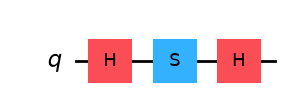

In [2]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit.quantum_info import Operator, Statevector

qc = QuantumCircuit(1)
qc.h(0)
qc.s(0)
qc.h(0)
print("Circuit unitary H S H:\n", np.round(Operator(qc).data, 4))
print("Output state from |0>:", np.round(Statevector(qc).data, 4))
qc.draw("mpl")

The circuit applies $H$, then $S$, then $H$, so its matrix is $HSH$ (with the first $H$ on the right, though here both ends are $H$). Is $HSH$ a gate we already know? Since $S = e^{i\pi/4}R_Z(\frac{\pi}{2})$ and $HZH = X$, we expect $HSH = e^{i\pi/4}R_X(\frac{\pi}{2})$. Qiskit can check this, ignoring global phase with `equiv`:

In [3]:
rx = QuantumCircuit(1)
rx.rx(np.pi / 2, 0)
print("HSH equals RX(pi/2) exactly?            ", np.allclose(Operator(qc).data, Operator(rx).data))
print("HSH equals RX(pi/2) up to global phase? ", Operator(qc).equiv(Operator(rx)))
print("HSH = e^{i pi/4} RX(pi/2)?               ", np.allclose(Operator(qc).data, np.exp(1j * np.pi / 4) * Operator(rx).data))

HSH equals RX(pi/2) exactly?             False
HSH equals RX(pi/2) up to global phase?  True
HSH = e^{i pi/4} RX(pi/2)?                True


### Checking identities and conventions

Here is a quick check of the identities from this workbook, including the $R_Z$ convention.

In [4]:
from qiskit.circuit.library import XGate, YGate, ZGate, HGate, SGate, TGate, RXGate, RYGate, RZGate, PhaseGate

M = {name: Operator(g).data for name, g in
     [("X", XGate()), ("Y", YGate()), ("Z", ZGate()), ("H", HGate()), ("S", SGate()), ("T", TGate())]}
t = 0.8
checks = {
    "HXH = Z": np.allclose(M["H"] @ M["X"] @ M["H"], M["Z"]),
    "HZH = X": np.allclose(M["H"] @ M["Z"] @ M["H"], M["X"]),
    "Y = iXZ": np.allclose(M["Y"], 1j * M["X"] @ M["Z"]),
    "T^2 = S, S^2 = Z": np.allclose(M["T"] @ M["T"], M["S"]) and np.allclose(M["S"] @ M["S"], M["Z"]),
    "RZ(t) = diag(e^{-it/2}, e^{it/2})": np.allclose(Operator(RZGate(t)).data, np.diag([np.exp(-1j*t/2), np.exp(1j*t/2)])),
    "RZ(t) = e^{-it/2} P(t)": np.allclose(Operator(RZGate(t)).data, np.exp(-1j*t/2) * Operator(PhaseGate(t)).data),
    "RX(pi) = -iX": np.allclose(Operator(RXGate(np.pi)).data, -1j * M["X"]),
    "RZ(2pi) = -I": np.allclose(Operator(RZGate(2*np.pi)).data, -np.eye(2)),
}
for k, v in checks.items():
    print(f"{k:36s} {v}")

HXH = Z                              True
HZH = X                              True
Y = iXZ                              True
T^2 = S, S^2 = Z                     True
RZ(t) = diag(e^{-it/2}, e^{it/2})    True
RZ(t) = e^{-it/2} P(t)               True
RX(pi) = -iX                         True
RZ(2pi) = -I                         True


### Running a circuit on the simulator

Now measure. Start in $|+\rangle$, rotate by $R_Z(\theta)$, then apply $H$ and measure (an X-basis measurement, as in Workbook 2). The state before $H$ is $\frac{1}{\sqrt2}(e^{-i\theta/2}|0\rangle + e^{i\theta/2}|1\rangle)$, and the Born rule gives

$$
P(0) = \left\lvert\frac{e^{-i\theta/2} + e^{i\theta/2}}{2}\right\rvert^2 = \cos^2\frac{\theta}{2}.
$$

A phase that was invisible in the Z basis now controls the outcome. We use the Aer simulator, which samples the exact probabilities on your computer. It is not quantum hardware.

 theta   P(0) predicted   P(0) from 2000 shots
 0.000        1.000            1.000
 1.047        0.750            0.755
 1.571        0.500            0.508
 2.094        0.250            0.253
 3.142        0.000            0.000


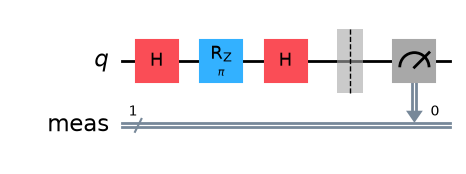

In [5]:
from qiskit_aer.primitives import SamplerV2 as Sampler

seed_source = np.random.default_rng(2027)

def run_counts(qc, shots=1000):
    """Run qc on the Aer simulator (not hardware) and return counts."""
    sampler = Sampler(seed=int(seed_source.integers(1_000_000)))
    return sampler.run([qc], shots=shots).result()[0].data.meas.get_counts()

print(" theta   P(0) predicted   P(0) from 2000 shots")
for theta in [0, np.pi / 3, np.pi / 2, 2 * np.pi / 3, np.pi]:
    circ = QuantumCircuit(1)
    circ.h(0)            # |0> -> |+>
    circ.rz(theta, 0)
    circ.h(0)            # X-basis measurement
    circ.measure_all()
    c = run_counts(circ, 2000)
    print(f"{theta:6.3f}   {np.cos(theta / 2)**2:10.3f}       {c.get('0', 0) / 2000:10.3f}")
circ.draw("mpl")

### Summary

- Gates are unitaries. Diagram order is left to right; matrix order is right to left.
- $X$ (bit flip), $Z$ (phase flip), $Y = iXZ$: half turns about $x$, $z$, $y$.
- $H$ swaps the Z and X bases. $H^2 = I$, $HXH = Z$, $HZH = X$.
- $S$, $T$, $P(\lambda)$ turn about $z$ and change only the relative phase. $T^2 = S$, $S^2 = Z$.
- $R_P(\theta) = \cos\frac{\theta}{2}I - i\sin\frac{\theta}{2}P$. Qiskit's $R_Z(\theta) = \mathrm{diag}(e^{-i\theta/2}, e^{i\theta/2}) = e^{-i\theta/2}P(\theta)$.
- Any single-qubit gate is $e^{i\alpha}R_Z(\beta)R_Y(\gamma)R_Z(\delta)$.
- `Operator(qc).equiv(...)` compares circuits up to global phase.

### References for this workbook

- J. D. Hidary, *Quantum Computing: An Applied Approach*, 2nd ed. (Springer, 2021): Ch. 3, Sec. 3.1 (quantum operators: unary operators), Secs. 3.3 and 3.4 (universality; Gottesman-Knill and Solovay-Kitaev, for later reading); Ch. 6, Secs. 6.3 (Qiskit) and 6.7 (gates with parameters); Ch. 15 (table of operators).
- M. A. Nielsen and I. L. Chuang, *Quantum Computation and Quantum Information*, 10th anniversary ed. (Cambridge, 2010): Sec. 1.3.1 (single qubit gates); Sec. 4.2 (single qubit operations); Sec. 2.1.3 (the Pauli matrices). Note that Nielsen and Chuang use their own rotation and phase conventions; compare with the Qiskit convention above.
- Y. Ding and F. T. Chong, *Quantum Computer Systems* (2020): Ch. 2 (Sec. 2.2) for gates; Ch. 5, "Quantum Programming Languages", for how circuits are expressed in software.
- J. Watrous, IBM Quantum Learning, *Basics of Quantum Information*, Lesson 1 "Single systems" (unitary operations) and Lesson 3 "Quantum circuits".
- Qiskit Textbook (legacy, archived 2024): chapter "Quantum States and Qubits", section "Single Qubit Gates". Its code uses older Qiskit APIs.

# Part B: Workbook exercises

E = easy, M = medium, H = hard, Q = Qiskit task. Use the Qiskit convention for $R_Z$ throughout.

## Easy

**E1.** Compute $X|{+i}\rangle$, $Z|-\rangle$ and $Y|0\rangle$. Write each answer as one of the six standard states times a phase.

**E2.** Show by matrix multiplication that $HZH = X$.

**E3.** Show that $S^2 = Z$ and $T^2 = S$. What is $T^8$?

**E4.** A circuit applies $H$, then $Z$, then $H$ to $|0\rangle$. Write the circuit's matrix in the correct order, and find the output state.

**E5.** Write the matrix $R_X(\pi)$ and show that it equals $-iX$. Do $R_X(\pi)$ and $X$ do the same thing to every state? Why?

**E6.** (Conceptual.) A friend says "after a $T$ gate on $|+\rangle$, the Z-basis histogram changes". Are they right? Explain using the Bloch sphere.

## Medium

**M1.** Compute $R_Y(\frac{\pi}{2})|0\rangle$ and $R_X(\frac{\pi}{2})|0\rangle$. Name both states.

**M2.** Find the global phase $e^{i\gamma}$ with $S = e^{i\gamma}R_Z(\frac{\pi}{2})$. Do the same for $T$ and $R_Z(\frac{\pi}{4})$.

**M3.** Start in $|+\rangle$. Apply $S$, then $S$ again. Where is the state on the Bloch sphere after each step? Check your answer with $S^2 = Z$.

**M4.** Find $\theta$ such that $R_Y(\theta)|0\rangle$ gives $P(1) = \frac14$. Then find $\varphi$ so that $P(\varphi)R_Y(\theta)|0\rangle$ is the state $\frac{\sqrt3}{2}|0\rangle - \frac{i}{2}|1\rangle$ from Workbook 2.

**M5.** Verify $XZ = -ZX$ and $XY = iZ$ by multiplication. Use them to simplify the circuit "$Z$, then $X$, then $Z$" to a single Pauli, up to sign.

**M6.** Find a sequence of gates from $\{H, S, S^\dagger, X, Z\}$ that takes $|0\rangle$ to $|{-i}\rangle$. Then find a single rotation gate that does the same.

## Hard

**H1.** Using $P^2 = I$ for $P \in \{X, Y, Z\}$, show that $e^{-i\theta P/2} = \cos\frac{\theta}{2}I - i\sin\frac{\theta}{2}P$. (Expand the exponential as a power series and split even and odd powers.) Check that this gives the matrices of Section 3.5.

**H2.** Show that $H R_Z(\theta) H = R_X(\theta)$. What does this say about rotations on the Bloch sphere?

**H3.** Show that $R_Z(\alpha)R_Z(\beta) = R_Z(\alpha + \beta)$, and that $R_Z(2\pi) = -I$. Explain why $-I$ is still "doing nothing" physically, but why it could matter if the gate were controlled by another qubit (one sentence; Workbook 6 returns to this).

**H4.** Find real angles with $H = e^{i\alpha}R_Z(\beta)R_Y(\gamma)R_Z(\delta)$. (Hint: try $\beta = 0$ and $\gamma = \frac{\pi}{2}$.)

## Qiskit tasks

**Q1.** Build the circuit "$H$, then $T$, then $H$". Print its unitary with `Operator`. Check with `equiv` that it equals $R_X(\frac{\pi}{4})$ up to global phase, and find the global phase.

In [6]:
# Q1: your code here

**Q2.** Start in $|0\rangle$, apply $R_X(\theta)$ and measure in the Z basis, for $\theta = 0, \frac{\pi}{4}, \frac{\pi}{2}, \frac{3\pi}{4}, \pi$. Predict $P(1)$ by hand, then check with 4000 shots on the simulator. Are all differences within 3 standard errors?

In [7]:
# Q2: your code here

**Q3.** Use `qiskit.synthesis.OneQubitEulerDecomposer("ZYZ")` and its method `angles_and_phase(U)` to find the angles for $H$ and for a random unitary from `qiskit.quantum_info.random_unitary(2, seed=5)`. The method returns `(theta, phi, lam, phase)` with $U = e^{i\,\text{phase}}R_Z(\text{phi})R_Y(\text{theta})R_Z(\text{lam})$. Rebuild each $U$ from the angles and check it matches.

In [8]:
# Q3: your code here

# Part C: Answer key

The answer key is in the instructor edition of this workbook.